# Lesson 13 pre-class prep: Reprojecting and merging

Before class, make sure you can import the data we will use in [lesson 13](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html). Run the four code cells in this notebook. If they all run without errors, you are ready for class!

## About the data

We will use three datasets:

1. **Arctic communities**: a GeoJSON file with the [list of Arctic communities and their location](https://search.dataone.org/view/doi%3A10.18739%2FA28S4JQ80), created by the [Alaska Native Tribal Health Consortium](https://www.anthc.org). We will read it directly from its URL, so you don't need to download it.

2. **Countries**: [Natural Earth's medium-scale cultural boundaries data for countries (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). [Natural Earth](https://www.naturalearthdata.com) is a public domain dataset with free, ready-to-use data for creating maps. To download it:
    1. Go to the [Natural Earth 1:50m cultural vectors page](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/).
    2. Under "Admin 0 – Countries", click on "Download countries".
    3. Unzip the file and move the `ne_50m_admin_0_countries` folder into a `data/` folder at the same level as this notebook.

3. **Country names**: a CSV with the country codes and names of the Arctic countries in the Arctic communities dataset. It was created for this lesson from the metadata of the Arctic communities dataset and the country names in Natural Earth's dataset. We will read it directly from its URL, so you don't need to download it.

Read the information about the datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html) before class.

## Import libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

## Import countries shapefile

In [2]:
fp = os.path.join('data', 'ne_50m_admin_0_countries', 'ne_50m_admin_0_countries.shp')
countries = gpd.read_file(fp)

# Simplify column names
countries.columns = countries.columns.str.lower()

# Select columns for analysis
countries = countries[['admin', 'type', 'geometry']]

countries.head(3)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

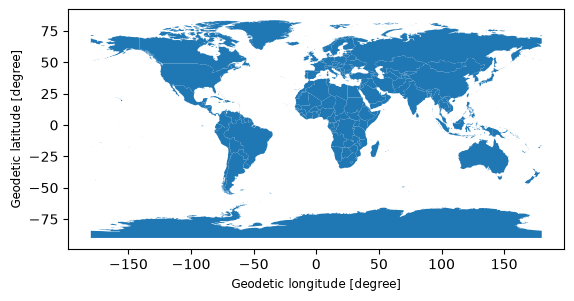

In [3]:
# Quick view
countries.plot()

## Import Arctic communities data

In [4]:
URL = 'https://cn.dataone.org/cn/v2/resolve/urn%3Auuid%3Aed7718ae-fb0d-43dd-9270-fbfe80bfc7a4'
communities = gpd.read_file(URL)

communities.head(3)

,name,population,country,geoname-id,geometry
0,Udomlya,32373,RU,452949,POINT (34.9925 57.87944)
1,Valmiera,26963,LV,453754,POINT (25.42751 57.54108)
2,Ventspils,42644,LV,454310,POINT (21.57288 57.38988)


In [5]:
# verify CRS match
assert countries.crs == communities.crs

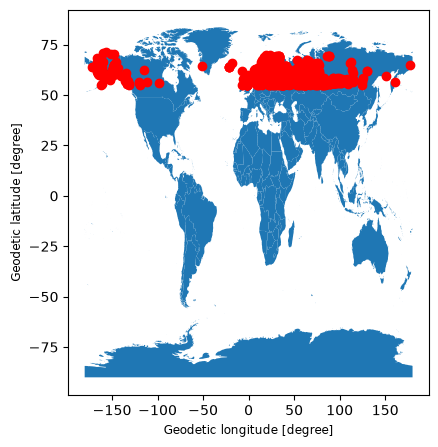

In [6]:
fig, ax = plt.subplots(figsize=(8,5))
countries.plot(ax=ax)
communities.plot(ax=ax, color = 'red')
plt.show()

## Import country names CSV

In [7]:
URL = 'https://raw.githubusercontent.com/MEDS-eds-220/MEDS-eds-220-course/refs/heads/main/book/chapters/lesson-12-merge-data/country_names.csv'
country_names = pd.read_csv(URL)

country_names.head(3)

,country,admin
0,RU,Russia
1,LV,Latvia
2,EE,Estonia


## Arctic communities by country

Next, we want to calculate the number of Arctic communities by country.



In [8]:
# Create dataframe with number of communities per country
n_comms = communities.groupby('country').size().reset_index(name = 'n_communities')
n_comms

,country,n_communities
0,AX,1
1,BY,8
2,CA,7
3,DK,72
4,EE,14
5,FI,98
6,FO,1
7,GB,96
8,GL,1
9,IS,5


## `if-else` statements

Our goal is to merge the `n_comms` and the `countries` data frames. To merge two data frames they need to have at least one column in common. Currently our datasets do not have any columns in common:



In [9]:
set(countries.columns).intersection(n_comms.columns)

set()

The output `set()` represents the empty set. This might not be as informative, so let’s write a different notification:



In [10]:
def check_common_columns(df1, df2):
    common_columns = set(df1.columns).intersection(df2.columns)

    # Check if there are any common columns
    if len(common_columns) != 0:
        print(f"Common columns: {common_columns}")
    else:
        print("No common columns")

## Merging data frames

We can use the `country_names` data frame to add the country names into the `n_comms` data which, in turn, will allow us to merge that data frame with the countries data. To merge data frames we can use the pandas.merge() function. The basic syntax for it is:

```{python}
output_df = pd.merge(left_df,
                     right_df, 
                     how = type_of_join, 
                     on = column_to_join)
```
where
- `output_df` is the data frame resulting from the merge,
- `left_df` is the data frame we have “on the left side”,
- `right_df` is the data frame we have “on the right side”,
- `how` specifies the type of join between the left and right data frames, (check the options here), the default is to do an inner join,
- `on` specifies the column to join on; this column must be present in both our data frames.

The `pandas.merge()` function is also available as a method of data frames:

```{python}
left_df.merge(right_df, how=..., on=...)
```

When one of the data frames is a `geopandas.GeoDataFrame`, GeoPandas recommends calling `merge()` from the geodataframe, so the output keeps its geometry. With `pd.merge()`, the geodataframe must be the left argument, otherwise you lose the geometry and the output is a plain `pandas.DataFrame`.

So, we merge the `n_comms` and `country_names` data frames using a left join:



In [11]:
n_comms = pd.merge(n_comms, country_names, how = 'left', on = 'country')
n_comms

,country,n_communities,admin
0,AX,1,Aland Islands
1,BY,8,Belarus
2,CA,7,Canada
3,DK,72,Denmark
4,EE,14,Estonia
5,FI,98,Finland
6,FO,1,Faroe Islands
7,GB,96,United Kingdom
8,GL,1,Greenland
9,IS,5,Iceland


In [12]:
check_common_columns(n_comms, countries)

Common columns: {'admin'}


### Check-in
Create a new variable named `arctic_countries` which is the result of an inner join between our `countries` and `n_comms` data frames. The inner join will merge the subset of rows that have matches in both the left table and the right table.

In [13]:
arctic_countries = pd.merge(n_comms, countries, how = 'inner')
arctic_countries

,country,n_communities,admin,type,geometry
0,BY,8,Belarus,Sovereign country,"POLYGON ((31.76338 52.10107, 31.57373 52.10811..."
1,CA,7,Canada,Sovereign country,"MULTIPOLYGON (((-132.65552 54.12749, -132.5640..."
2,DK,72,Denmark,Country,"MULTIPOLYGON (((12.56875 55.78506, 12.57119 55..."
3,EE,14,Estonia,Sovereign country,"MULTIPOLYGON (((27.35195 57.52812, 27.32656 57..."
4,FI,98,Finland,Country,"MULTIPOLYGON (((24.15547 65.80527, 24.04902 65..."
5,FO,1,Faroe Islands,Dependency,"MULTIPOLYGON (((-6.62319 61.80596, -6.64277 61..."
6,GB,96,United Kingdom,Country,"MULTIPOLYGON (((-2.66768 51.623, -2.74214 51.5..."
7,GL,1,Greenland,Country,"MULTIPOLYGON (((-29.95288 83.56484, -28.99199 ..."
8,IS,5,Iceland,Sovereign country,"POLYGON ((-15.54312 66.22852, -15.42847 66.224..."
9,LT,26,Lithuania,Sovereign country,"MULTIPOLYGON (((20.95781 55.27891, 20.8998 55...."


## Reviewing results

It is always a good idea to check the number of rows after a merge. Our `n_comms` data frame has one row per country, but the merged data frame has one row less:



In [14]:
print(f"Countries in n_comms: {len(n_comms)}")
print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in n_comms: 16
Countries in arctic_countries: 15


An inner join only keeps the rows that have a match in both data frames, so one country in `n_comms` had no match in `countries`. We can find it using `isin()`:



In [15]:
# Find which row is not in arctic_countries
n_comms[~n_comms['admin'].isin(countries['admin'])]

,country,n_communities,admin
0,AX,1,Aland Islands


The Aland Islands are an autonomous region of Finland and there is one Arctic community registered in this region. Like the Faroe Islands and Greenland, the Aland Islands have their own country code in the Arctic communities data and their own polygon in Natural Earth’s data. So why didn’t they match? Let’s look for them in the `countries` data frame:



In [16]:
countries[countries['admin'].str.contains('Aland')]

,admin,type,geometry
168,Aland,Country,"MULTIPOLYGON (((19.98955 60.35117, 20.02021 60..."


Natural Earth’s data calls this region ‘Aland’, while our `country_names` data uses ‘Aland Islands’. The values in the column we join on must match exactly for the merge to find them. We update the name in `n_comms` to match the `countries` data and merge again:



In [17]:
n_comms['admin'] = n_comms['admin'].replace('Aland Islands','Aland')

# merge again
arctic_countries = pd.merge(countries, n_comms, how='inner', on='admin')

print(f"Countries in arctic_countries: {len(arctic_countries)}")


Countries in arctic_countries: 16


### Checking with `indicator=True`

Another way to find rows without a match is to add `indicator=True` to the merge. This creates a `_merge` column that says whether each row was found in both data frames or only in one of them:



In [18]:
left = pd.DataFrame({'key': ['a', 'b', 'c'], 'x': [1, 2, 3]})
right = pd.DataFrame({'key': ['a', 'b', 'd'], 'y': [4, 5, 6]})

pd.merge(left, right, how='outer', on='key', indicator=True)

,key,x,y,_merge
0,a,1.0,4.0,both
1,b,2.0,5.0,both
2,c,3.0,NaN,left_only
3,d,NaN,6.0,right_only


## Choropleth map

A [choropleth](https://en.wikipedia.org/wiki/Choropleth_map) map is an efficient way to visualize aggregate data per region.

Making a choropleth map from our polygons `GeoDataFrame` is easy; we just need to specify the `column` parameter in `plot()` and make it equal to the column with the values we want to plot in each country:



<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

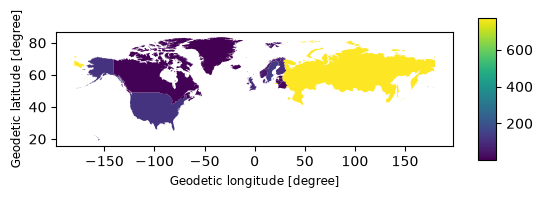

In [19]:
arctic_countries.plot(column='n_communities',
                      legend=True)

## Reprojecting

Remember that CRSs reflect cultural views and even biases. Any map projection involves choices about which areas to emphasize, minimize, or distort, and those choices can influence how viewers perceive different regions. In our map, using the EPSG:4326 CRS is, among other things, mapping the Arctic regions as far apart, while they are actually near each other.

**Reprojecting** means changing the coordinate reference system of your geospatial data. In our case, we will reproject the arctic_countries geodataframe to the CRS EPSG:3413. This CRS is a projected CRS, better suited for working with data from the Arctic region:



Changing CRSs in GeoPandas is very simple using the `to_crs()` method for `geopandas.GeoDataFrames`. The general syntax is:

```
updated_geodf = geodf.to_crs(new_crs)
```

where:

- `updated_geodf` is the output of the method, a new geodataframe (to_crs() does not work in place),
- `geodf` is the geopandas.GeoDataFrame we want to transform,
- `new_crs` is the CRS we want to convert to; this is an object of type CRS or a string representing the CRS (ex: 'epsg:3413').

In [20]:
arctic_countries = arctic_countries.to_crs('epsg:3414')

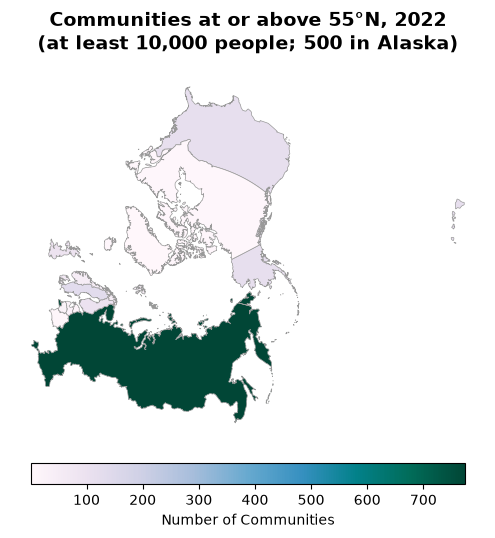

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))

# Remove the axis for a cleaner map
ax.axis('off')

# Create choropleth map of communities
# Plot with refined color and edge style
arctic_countries.plot(
    ax=ax,
    column='n_communities',
    cmap='PuBuGn',
    legend=True,
    edgecolor="0.6",
    linewidth=0.5,
    legend_kwds={
        "shrink": 0.7,
        "label": "Number of Communities",
        "orientation": "horizontal",
        "pad": 0.05
    }
)

# Add title for better context
ax.set_title('Communities at or above 55°N, 2022\n(at least 10,000 people; 500 in Alaska)',
             fontsize=14, weight='bold', pad=15)

plt.show()